# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'jhaff2'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

244 epochs over 968 days; median quoted error 0.040 mag; rms of the light curve 0.262 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


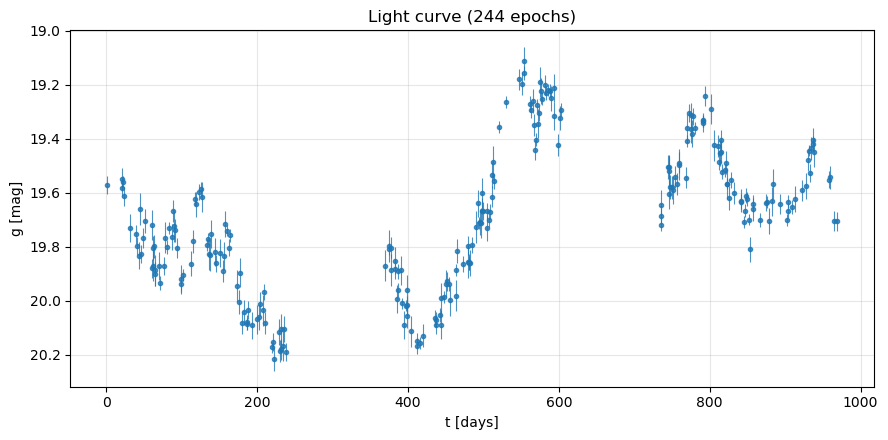

grid: 465 frequencies, df = 1.03e-04 1/d (required <= 2.07e-04)
HIGHEST PEAK: P = 236.1 d, power = 0.4095, astropy FAP (baluev) = 1.26e-25
  FAP (davies) = 1.26e-25
  FAP (bootstrap, shuffles the data = white-noise null) = 0

 rank  period[d]  power   alias of best peak? (f_best +/- window peak)
   1      236.1  0.4095  -
   2      111.3  0.0947  -
   3      158.7  0.0523  -
   4      132.6  0.0420  -
   5       22.9  0.0399  -
   6       29.3  0.0387  -
   7       51.8  0.0381  -
   8       75.1  0.0336  -


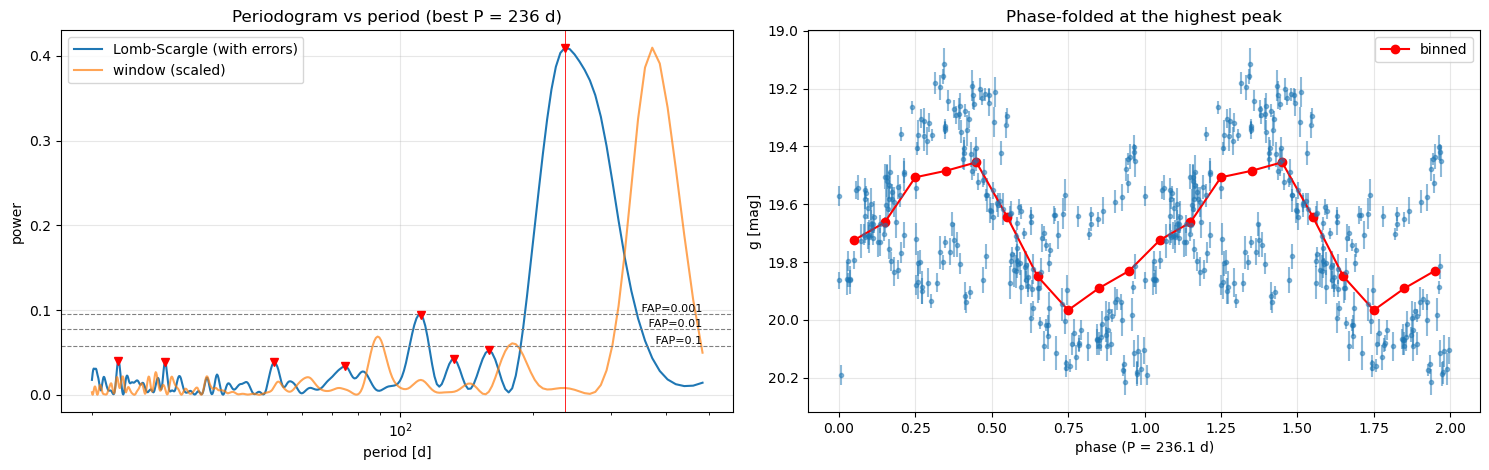

In [2]:
# ===================== Part 1: look first, periodogram, window =====================
from scipy.signal import find_peaks
from scipy.linalg import solve_triangular, LinAlgError
from scipy.stats import norm, probplot
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
N = t.size

# ---- 1a. The light curve and basic diagnostics ----
def structure_function(tt, yy, ee, bins):
    """D(lag) = <(y_i-y_j)^2> - <e_i^2+e_j^2> in log-spaced lag bins (for a GP, D = 2[k(0)-k(lag)])."""
    i, j = np.triu_indices(len(tt), 1)
    lag = np.abs(tt[i] - tt[j]); dy2 = (yy[i] - yy[j])**2 - (ee[i]**2 + ee[j]**2)
    idx = np.digitize(lag, bins) - 1
    lc, D, De = [], [], []
    for b in range(len(bins) - 1):
        m = idx == b
        if m.sum() > 20:
            lc.append(np.exp(np.mean(np.log(lag[m])))); D.append(dy2[m].mean()); De.append(dy2[m].std() / np.sqrt(m.sum()))
    return np.array(lc), np.array(D), np.array(De)

dts = np.diff(t)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(t, y, e, fmt='o', ms=3, lw=0.8, alpha=0.8, color='C0')
ax.invert_yaxis(); ax.set(xlabel='t [days]', ylabel='g [mag]', title=f'Light curve ({N} epochs)')
plt.tight_layout(); plt.show()

bins_sf = np.logspace(np.log10(max(1.0, np.median(dts) / 2)), np.log10(T), 18)
lag_sf, D_sf, De_sf = structure_function(t, y, e, bins_sf)

# ---- 1b. Lomb-Scargle periodogram and the window function ----
fmin, fmax = 2.0 / T, 1.0 / 20.0           # periods 20 d ... T/2
df = 1.0 / (10 * T)                         # finer than the required 1/(5T)
freq = np.arange(fmin, fmax + df / 2, df); period = 1 / freq
ls = LombScargle(t, y, e)
power = ls.power(freq)
win = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).power(freq)
win_s = win * power.max() / win.max()       # same maximum as the periodogram

ipk = np.argmax(power); f_best, P_best = freq[ipk], period[ipk]
fap_astropy = ls.false_alarm_probability(power[ipk], minimum_frequency=fmin, maximum_frequency=fmax)
print(f"grid: {freq.size} frequencies, df = {df:.2e} 1/d (required <= {1/(5*T):.2e})")
print(f"HIGHEST PEAK: P = {P_best:.1f} d, power = {power[ipk]:.4f}, astropy FAP (baluev) = {fap_astropy:.3g}")
for meth in ['davies']:
    try: print(f"  FAP ({meth}) = {ls.false_alarm_probability(power[ipk], minimum_frequency=fmin, maximum_frequency=fmax, method=meth):.3g}")
    except Exception as ex: print('  FAP', meth, 'failed:', ex)
try:
    fb = ls.false_alarm_probability(power[ipk], minimum_frequency=fmin, maximum_frequency=fmax, method='bootstrap', method_kwds=dict(n_bootstraps=300, random_seed=0))
    print(f"  FAP (bootstrap, shuffles the data = white-noise null) = {fb:.3g}")
except Exception as ex: print('  bootstrap FAP failed:', ex)

# peaks of the periodogram, and which are aliases (beat frequencies with window peaks)
fw = np.arange(df, 0.1, df / 2)
winwide = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).power(fw)
wpk, _ = find_peaks(winwide, height=0.15 * winwide.max())
f_win_peaks = fw[wpk]
pk, _ = find_peaks(power); pk = pk[np.argsort(power[pk])[::-1]][:8]
print("\n rank  period[d]  power   alias of best peak? (f_best +/- window peak)")
for r, k in enumerate(pk):
    tag = '-'
    if k != ipk:
        for fwp in f_win_peaks:
            for s_ in (+1, -1):
                if abs(freq[k] - (f_best + s_ * fwp)) < 2 * df:
                    tag = f"yes: f_best {'+' if s_>0 else '-'} 1/{1/fwp:.0f} d"
    print(f" {r+1:3d}  {period[k]:9.1f}  {power[k]:.4f}  {tag}")

fap_lv = [0.1, 0.01, 0.001]
lev = ls.false_alarm_level(fap_lv, minimum_frequency=fmin, maximum_frequency=fmax)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axs[0]
ax.plot(period, power, label='Lomb-Scargle (with errors)'); ax.plot(period, win_s, alpha=0.7, label='window (scaled)')
for l_, fp_ in zip(lev, fap_lv): ax.axhline(l_, ls='--', lw=0.8, color='gray'); ax.text(period.max(), l_, f' FAP={fp_}', va='bottom', ha='right', fontsize=8)
ax.plot(period[pk], power[pk], 'rv'); ax.axvline(P_best, color='r', lw=0.6)
ax.set(xscale='log', xlabel='period [d]', ylabel='power', title=f'Periodogram vs period (best P = {P_best:.0f} d)'); ax.legend()
ax = axs[1]
ph = ((t - t.min()) / P_best) % 1
ax.errorbar(np.r_[ph, ph + 1], np.r_[y, y], np.r_[e, e], fmt='.', alpha=0.5)
nb = 10; bi = np.minimum((ph * nb).astype(int), nb - 1)
bm = [np.average(y[bi == b], weights=1 / e[bi == b]**2) if (bi == b).any() else np.nan for b in range(nb)]
ax.plot(np.r_[(np.arange(nb) + .5) / nb, (np.arange(nb) + .5) / nb + 1], np.r_[bm, bm], 'ro-', label='binned')
ax.invert_yaxis(); ax.set(xlabel=f'phase (P = {P_best:.1f} d)', ylabel='g [mag]', title='Phase-folded at the highest peak'); ax.legend()
plt.tight_layout(); plt.show()

**ANSWER (a few sentences):**

Highest period is 236.1, with a powr of 0.4095. This peak is super large considering it covers almost a year, which we only have data for less than 1000 days not even incluidng the missing seasons. There are other alias peaks at 158.7  and 111 days, and 132 days, etc. 

It has a FAP value of 1.26e-25, which I already don't trust based on vibes alone. Thats way too confident. This is because the astropy FAP isn't counting other types of scatter other than the errirbars on the x axis (sigma x) given and assumes it is just that white noise. Pulsars are chaotic and have underlying uncertain periods, so this interpretation is wrong.

We need T/2 because otherwise two peaks would be indisingushible, and any higher of a T, we might get more error and less return.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


DRW maximum-likelihood from 12 starting points (several starts guard against local maxima / the flat tau ridge):
 start(sig,tau)      lnL        mu       sigma     tau
 (0.20,  800)    316.1732   19.6904   0.2579     148.4
 (0.05,  150)    316.1732   19.6904   0.2579     148.3
 (0.20,  150)    316.1732   19.6904   0.2579     148.3
 (0.60,  150)    316.1732   19.6904   0.2579     148.3
 (0.60,   20)    316.1732   19.6904   0.2579     148.3
 (0.05, 3000)    316.1732   19.6904   0.2579     148.3
 (0.60,  800)    316.1732   19.6904   0.2579     148.3
 (0.05,  800)    316.1732   19.6904   0.2579     148.3
 (0.20,   20)    316.1732   19.6904   0.2579     148.3
 (0.60, 3000)    316.1732   19.6904   0.2579     148.4
 (0.20, 3000)    316.1732   19.6904   0.2579     148.3
 (0.05,   20)    316.1732   19.6904   0.2579     148.3

BEST DRW: lnL = 316.173, mu = 19.6904, sigma = 0.2579, tau = 148.4 d
Profile-likelihood tau: best 155 d, 68% interval [96, 291] d  (None = not bounded inside the 10-4000 d

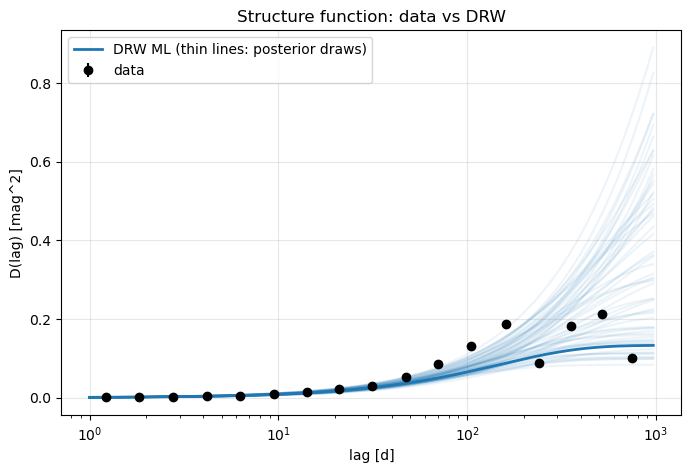

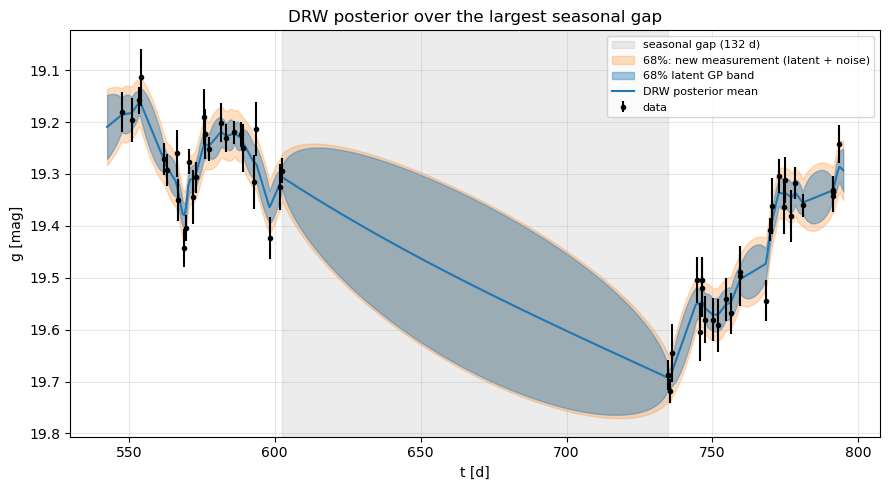

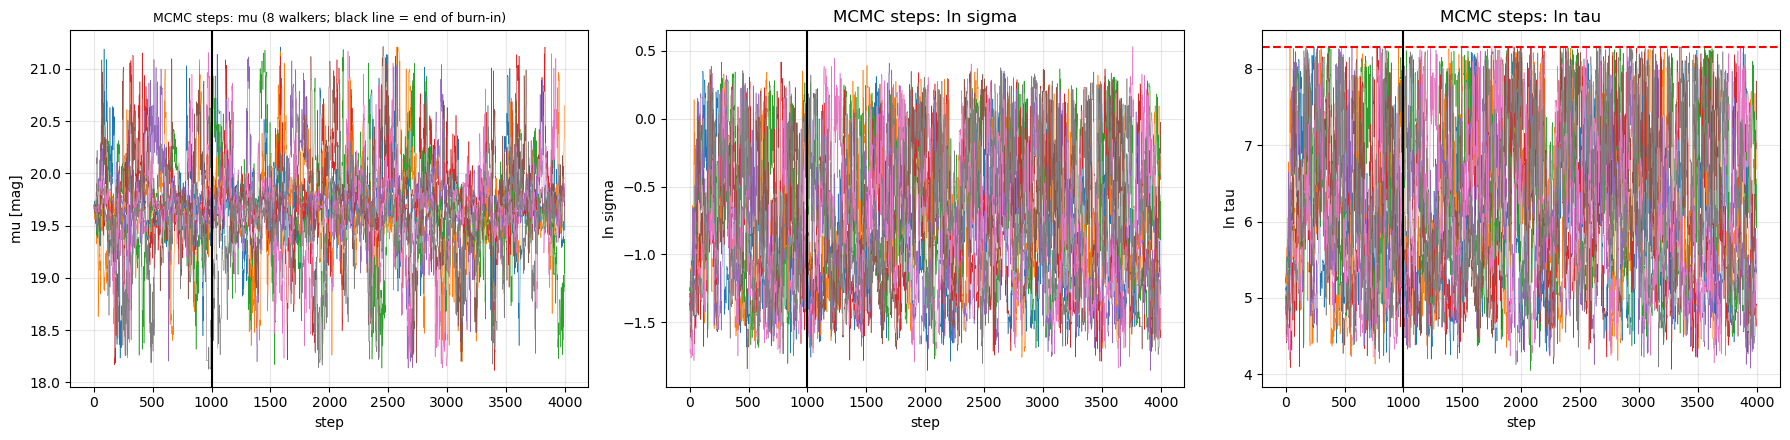

The bands above: DRW/SE 'latent' = the true underlying light curve; the wider 'new measurement' band adds the per-epoch noise. Data points scatter around the latent curve by their measurement error, so ~68% of data should lie within the wider band, but a latent band should NOT be used to judge held-out data (it would show too few points inside).

Seasons found (start, end) [d]: [(1, 238), (369, 603), (735, 969)]
block starts [d]: [166.3 439.3 561.8 913.2]; held out 47 of 244 points; training on 197
 DRW: train-fit sigma=0.257, scale=145.3 d | n_held = 47, inside 68% predictive band = 0.57 (27/47), inside latent-only band = 0.57, R2 vs training mean = 0.901, std(z) = 1.04
 SE: train-fit sigma=0.234, scale=14.2 d | n_held = 47, inside 68% predictive band = 0.89 (42/47), inside latent-only band = 0.87, R2 vs training mean = 0.938, std(z) = 0.63

=== FINAL ANSWER (numbers to paste) ===
sigma = 0.431 (+0.403 / -0.162) mag, tau = 421 (+1164 / -260) d, T/tau = 2.30 (+3.74 / -1.69); the expone

In [3]:
# ===================== Part 2: the Gaussian process =====================
from scipy.optimize import minimize_scalar
trapz = getattr(np, 'trapezoid', None) or np.trapz
LNS_B = (np.log(0.01), np.log(3.0))       # 0.01 < sigma < 3 mag
LNT_B = (np.log(10.0), np.log(4000.0))    # 10 < tau < 4000 d
# Priors: uniform in ln(sigma) and ln(tau) (scale parameters -> scale-invariant/Jeffreys-like);
# sigma floor 0.01 ~ below any plausible variability given ~0.02-0.04 mag errors, ceiling 3 mag >> any quasar rms;
# tau floor 10 d ~ cadence-ish (can't be probed below that), ceiling 4000 d ~ 4x the baseline (beyond that the
# light curve is indistinguishable from a linear trend / random walk with a longer tau).  Flat mean: broad uniform.

def drw_k(dt, sig, tau): return sig**2 * np.exp(-np.abs(dt) / tau)
def se_k(dt, sig, ell):  return sig**2 * np.exp(-0.5 * (dt / ell)**2)
KERN = {'DRW': drw_k, 'SE': se_k}

def cov(tt, ee, kern, sig, tau):
    C = KERN[kern](tt[:, None] - tt[None, :], sig, tau)
    C[np.diag_indices_from(C)] += ee**2
    return C

def log_like(theta, tt, yy, ee, kern='DRW'):
    mu, ls_, lt_ = theta
    try: cf = cho_factor(cov(tt, ee, kern, np.exp(ls_), np.exp(lt_)), lower=True, check_finite=False)
    except (LinAlgError, ValueError): return -np.inf
    r = yy - mu
    return -0.5 * r @ cho_solve(cf, r, check_finite=False) - np.sum(np.log(np.diag(cf[0]))) - 0.5 * len(yy) * np.log(2 * np.pi)

def log_prior(theta, yy):
    mu, ls_, lt_ = theta
    ok = (yy.min() - 1 < mu < yy.max() + 1) and (LNS_B[0] < ls_ < LNS_B[1]) and (LNT_B[0] < lt_ < LNT_B[1])
    return 0.0 if ok else -np.inf

def log_post(theta, tt, yy, ee, kern='DRW'):
    lp = log_prior(theta, yy)
    if not np.isfinite(lp): return -np.inf
    ll = log_like(theta, tt, yy, ee, kern)
    return lp + ll if np.isfinite(ll) else -np.inf

def fit_ml(tt, yy, ee, kern='DRW', starts=None):
    """Maximum likelihood (= max posterior, flat priors) from several starting values; returns list sorted best-first."""
    mu0 = np.average(yy, weights=1 / ee**2)
    if starts is None:
        starts = [(a, b) for a in np.log([0.05, 0.2, 0.6]) for b in np.log([20, 150, 800, 3000])]
    nll = lambda th: -lp if np.isfinite(lp := log_post(th, tt, yy, ee, kern)) else 1e25
    out = []
    for a, b in starts:
        r = minimize(nll, [mu0, a, b], method='Nelder-Mead', options=dict(xatol=1e-4, fatol=1e-7, maxiter=3000, maxfev=3000))
        out.append((-r.fun, r.x, (a, b)))
    out.sort(key=lambda z: -z[0]); return out

def gp_predict(ts, tt, yy, ee, kern, theta, full_cov=False):
    """Posterior mean and variance (or covariance) of the LATENT process at ts (mean mu held at its ML value)."""
    mu, ls_, lt_ = theta; sig, tau = np.exp(ls_), np.exp(lt_); k = KERN[kern]
    cf = cho_factor(cov(tt, ee, kern, sig, tau), lower=True)
    Ks = k(ts[:, None] - tt[None, :], sig, tau)
    m = mu + Ks @ cho_solve(cf, yy - mu); V = cho_solve(cf, Ks.T)
    if full_cov: return m, k(ts[:, None] - ts[None, :], sig, tau) - Ks @ V
    return m, np.clip(sig**2 - np.einsum('ij,ji->i', Ks, V), 0, None)

# ---- 2.2 maximum likelihood from many starts ----
ml_drw = fit_ml(t, y, e, 'DRW')
print("DRW maximum-likelihood from 12 starting points (several starts guard against local maxima / the flat tau ridge):")
print(" start(sig,tau)      lnL        mu       sigma     tau")
for lnl, th, st in ml_drw:
    print(f" ({np.exp(st[0]):.2f},{np.exp(st[1]):5.0f})  {lnl:10.4f}  {th[0]:8.4f}  {np.exp(th[1]):7.4f}  {np.exp(th[2]):8.1f}")
lnL_drw, th_drw = ml_drw[0][0], ml_drw[0][1]
MU_ML, SIG_ML, TAU_ML = th_drw[0], np.exp(th_drw[1]), np.exp(th_drw[2])
print(f"\nBEST DRW: lnL = {lnL_drw:.3f}, mu = {MU_ML:.4f}, sigma = {SIG_ML:.4f}, tau = {TAU_ML:.1f} d")

# ---- profile likelihood over tau (mu profiled analytically by GLS, sigma by 1-D optimisation) ----
def prof_at_tau(tau, tt, yy, ee, kern='DRW'):
    ones = np.ones(len(yy))
    def parts(ls_):
        cf = cho_factor(cov(tt, ee, kern, np.exp(ls_), tau), lower=True)
        ci1, ciy = cho_solve(cf, ones), cho_solve(cf, yy); mu = (ones @ ciy) / (ones @ ci1)
        return mu, log_like([mu, ls_, np.log(tau)], tt, yy, ee, kern)
    r = minimize_scalar(lambda ls_: -parts(ls_)[1], bounds=LNS_B, method='bounded', options=dict(xatol=1e-4))
    mu, ll = parts(r.x); return ll, np.exp(r.x), mu

taus = np.logspace(1, np.log10(4000), 60)
prof = np.array([prof_at_tau(tau, t, y, e) for tau in taus])
lnL_prof, sig_prof, mu_prof = prof.T
dchi = 2 * (max(lnL_prof.max(), lnL_drw) - lnL_prof)

def profile_interval(x, d, level=1.0):
    i0 = np.argmin(d); lo = hi = None
    for i in range(i0, 0, -1):
        if d[i - 1] > level: lo = np.interp(level, [d[i], d[i - 1]], [x[i], x[i - 1]]); break
    for i in range(i0, len(x) - 1):
        if d[i + 1] > level: hi = np.interp(level, [d[i], d[i + 1]], [x[i], x[i + 1]]); break
    return lo, x[i0], hi
lo_, best_, hi_ = profile_interval(np.log(taus), dchi)
print("Profile-likelihood tau: best %.0f d, 68%% interval [%s, %s] d  (None = not bounded inside the 10-4000 d prior range)" %
      (np.exp(best_), None if lo_ is None else f"{np.exp(lo_):.0f}", None if hi_ is None else f"{np.exp(hi_):.0f}"))

# ---- likelihood surface in (ln sigma, ln tau), mu profiled ----
gs_, gt_ = np.linspace(np.log(0.03), np.log(1.0), 45), np.linspace(LNT_B[0], LNT_B[1], 55)
ones = np.ones(N); surf = np.empty((gs_.size, gt_.size))
for i, a in enumerate(gs_):
    for j, b in enumerate(gt_):
        cf = cho_factor(cov(t, e, 'DRW', np.exp(a), np.exp(b)), lower=True)
        mu = ones @ cho_solve(cf, y) / (ones @ cho_solve(cf, ones)); surf[i, j] = log_like([mu, a, b], t, y, e, 'DRW')
dsurf = 2 * (surf.max() - surf)

# ---- 2.2 MCMC with emcee ----
NWALK, NSTEPS, NBURN = 32, 4000, 1000
rng = np.random.default_rng(1)
p0 = []
while len(p0) < NWALK:
    c = th_drw + np.array([0.02, 0.1, 0.3]) * rng.standard_normal(3)
    if np.isfinite(log_post(c, t, y, e, 'DRW')): p0.append(c)
sampler = emcee.EnsembleSampler(NWALK, 3, log_post, args=(t, y, e, 'DRW'))
sampler.run_mcmc(np.array(p0), NSTEPS, progress=False)
chain = sampler.get_chain()                          # (steps, walkers, 3)

def acf_1d(x):
    x = x - x.mean(); n = len(x); f = np.fft.fft(x, n=2 * n); a = np.fft.ifft(f * np.conj(f))[:n].real; return a / a[0]
def tau_int(ch):                                     # ch: (steps, walkers); Sokal window c = 5
    a = np.mean([acf_1d(ch[:, w]) for w in range(ch.shape[1])], axis=0); tt_ = 2 * np.cumsum(a) - 1
    m = np.arange(len(tt_)) < 5 * tt_; w = np.argmin(m) if (~m).any() else len(tt_) - 1
    return tt_[w]
def split_rhat(ch):                                  # ch: (steps, walkers) post-burn
    n = ch.shape[0] // 2; c = np.concatenate([ch[:n], ch[n:2 * n]], axis=1)
    W = c.var(axis=0, ddof=1).mean(); B = n * c.mean(axis=0).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

post = chain[NBURN:]
names = ['mu', 'ln sigma', 'ln tau']
print("\nMCMC convergence checks (post burn-in):")
print(f" acceptance fraction: {np.mean(sampler.acceptance_fraction):.2f}")
for k, nm in enumerate(names):
    ta = tau_int(post[:, :, k]); r = split_rhat(post[:, :, k])
    h1, h2 = np.median(post[:len(post)//2, :, k]), np.median(post[len(post)//2:, :, k])
    print(f" {nm:9s}: autocorr time = {ta:6.1f} steps (chain is {post.shape[0]/ta:5.0f} tau long; want > 50), split-Rhat = {r:.3f}, median 1st/2nd half = {h1:.3f}/{h2:.3f}")

flat = sampler.get_chain(discard=NBURN, thin=5, flat=True)
mu_s, sig_s, tau_s = flat[:, 0], np.exp(flat[:, 1]), np.exp(flat[:, 2])
def summ(x, nm, fmt='.4f'):
    lo, md, hi = np.percentile(x, [16, 50, 84]); print(f" {nm:8s} = {md:{fmt}}  +{hi-md:{fmt}} / -{md-lo:{fmt}}"); return lo, md, hi
print("\nPosterior (median, 68% interval):")
mu_q = summ(mu_s, 'mu'); sig_q = summ(sig_s, 'sigma'); tau_q = summ(tau_s, 'tau', '.1f')
lt_q = summ(flat[:, 2], 'ln tau'); Ttau_q = summ(T / tau_s, 'T/tau', '.2f')
print(f" ln-tau interval width = {lt_q[2]-lt_q[0]:.2f}  (grader's cap: 3 x reference width)")
print(f" fraction of posterior with tau > 0.9 * upper bound (prior is pushing the result): {np.mean(tau_s > 0.9 * 4000):.3f}")
print(f" fraction with tau < 1.1 * lower bound: {np.mean(tau_s < 1.1 * 10):.3f}")

# ---- 2.3 squared-exponential kernel ----
ml_se = fit_ml(t, y, e, 'SE')
lnL_se, th_se = ml_se[0][0], ml_se[0][1]
SIG_SE, ELL_SE = np.exp(th_se[1]), np.exp(th_se[2])
print(f"\nBEST SE : lnL = {lnL_se:.3f}, mu = {th_se[0]:.4f}, sigma = {SIG_SE:.4f}, ell = {ELL_SE:.1f} d")
print(f"Delta lnL (DRW - SE) = {lnL_drw - lnL_se:.2f}   (positive => exponential kernel preferred; same number of parameters)")
best_kern = 'DRW' if lnL_drw >= lnL_se else 'SE'
theta_best = {'DRW': th_drw, 'SE': th_se}

# ---- Figure 1: DRW fit vs the structure function ----
lagg = np.logspace(0, np.log10(T), 200); fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(lag_sf, D_sf, De_sf, fmt='ko', label='data')
for i in rng.choice(len(flat), 60, replace=False): ax.plot(lagg, 2 * np.exp(2 * flat[i, 1]) * (1 - np.exp(-lagg / np.exp(flat[i, 2]))), 'C0', alpha=0.08)
ax.plot(lagg, 2 * SIG_ML**2 * (1 - np.exp(-lagg / TAU_ML)), 'C0', lw=2, label='DRW ML (thin lines: posterior draws)')
ax.set(xscale='log', xlabel='lag [d]', ylabel='D(lag) [mag^2]', title='Structure function: data vs DRW'); ax.legend(); plt.show()

# ---- Figure 2: DRW prediction across the largest seasonal gap ----
ig = np.argmax(np.diff(t)); tg = np.linspace(t[ig] - 60, t[ig + 1] + 60, 400)
e_med = np.median(e)
m, v = gp_predict(tg, t, y, e, 'DRW', theta_best['DRW']); sd = np.sqrt(v); sdn = np.sqrt(v + e_med**2)
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(t[ig], t[ig + 1], color='gray', alpha=0.15, label=f'seasonal gap ({t[ig+1]-t[ig]:.0f} d)')
ax.fill_between(tg, m - sdn, m + sdn, color='C1', alpha=0.25, label='68%: new measurement (latent + noise)')
ax.fill_between(tg, m - sd, m + sd, color='C0', alpha=0.4, label='68% latent GP band')
ax.plot(tg, m, 'C0', label='DRW posterior mean'); sel = (t > tg[0]) & (t < tg[-1]); ax.errorbar(t[sel], y[sel], e[sel], fmt='k.', label='data')
ax.invert_yaxis(); ax.set(xlabel='t [d]', ylabel='g [mag]', title='DRW posterior over the largest seasonal gap'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Figure 3: MCMC steps ----
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for k, (nm, ax) in enumerate(zip(['mu [mag]', 'ln sigma', 'ln tau'], axs)):
    for w in range(min(8, NWALK)): ax.plot(chain[:, w, k], lw=0.4)
    ax.axvline(NBURN, color='k'); ax.set(xlabel='step', ylabel=nm, title=f'MCMC steps: {nm}')
axs[2].axhline(LNT_B[1], color='r', ls='--')
axs[0].set_title('MCMC steps: mu (8 walkers; black line = end of burn-in)', fontsize=9)
plt.tight_layout(); plt.show()
print("The bands above: DRW/SE 'latent' = the true underlying light curve; the wider 'new measurement' band adds the "
      "per-epoch noise. Data points scatter around the latent curve by their measurement error, so ~68% of data should lie within the "
      "wider band, but a latent band should NOT be used to judge held-out data (it would show too few points inside).")

# ---- 2.5 held-out blocks ----
gaps_ = np.diff(t); brk = np.sort(np.argsort(gaps_)[-2:])
edges = [0] + list(brk + 1) + [N]; seasons = [(t[a], t[b - 1]) for a, b in zip(edges[:-1], edges[1:])]
print("\nSeasons found (start, end) [d]:", [(round(a), round(b)) for a, b in seasons])
BL, SEP = 30.0, 60.0
def draw_blocks(rng_, nblock=4):
    for _ in range(200000):
        st = []
        for _ in range(nblock):
            a, b = seasons[rng_.integers(len(seasons))]
            if b - a < BL: break
            st.append(rng_.uniform(a, b - BL))
        else:
            st = np.sort(st)
            inside = [((t >= s) & (t < s + BL)).sum() for s in st]
            if np.all(st[1:] - (st[:-1] + BL) >= SEP) and min(inside) >= 5: return st
    raise RuntimeError('could not draw blocks')
rng_cv = np.random.default_rng(2026); block_starts = draw_blocks(rng_cv)
held = np.zeros(N, bool)
for s in block_starts: held |= (t >= s) & (t < s + BL)
tr = ~held
print(f"block starts [d]: {np.round(block_starts, 1)}; held out {held.sum()} of {N} points; training on {tr.sum()}")

cv_res = {}
for kn in ['DRW', 'SE']:
    fit = fit_ml(t[tr], y[tr], e[tr], kn, starts=[(np.log(s_), np.log(l_)) for s_ in [0.1, 0.3] for l_ in [30, 200, 1000]])
    th_ = fit[0][1]; m, v = gp_predict(t[held], t[tr], y[tr], e[tr], kn, th_)
    tot = np.sqrt(v + e[held]**2); r = y[held] - m
    inside = np.abs(r) < tot; inside_lat = np.abs(r) < np.sqrt(v)
    R2 = 1 - np.sum(r**2) / np.sum((y[held] - y[tr].mean())**2)
    cv_res[kn] = dict(theta=th_, m=m, v=v, tot=tot, r=r, inside=inside, inside_lat=inside_lat, R2=R2, z=r / tot)
    print(f" {kn}: train-fit sigma={np.exp(th_[1]):.3f}, scale={np.exp(th_[2]):.1f} d | n_held = {held.sum()}, "
          f"inside 68% predictive band = {inside.mean():.2f} ({inside.sum()}/{held.sum()}), inside latent-only band = {inside_lat.mean():.2f}, R2 vs training mean = {R2:.3f}, std(z) = {np.std(r/tot):.2f}")

print("\n=== FINAL ANSWER (numbers to paste) ===")
print(f"sigma = {sig_q[1]:.3f} (+{sig_q[2]-sig_q[1]:.3f} / -{sig_q[1]-sig_q[0]:.3f}) mag, tau = {tau_q[1]:.0f} (+{tau_q[2]-tau_q[1]:.0f} / -{tau_q[1]-tau_q[0]:.0f}) d, "
      f"T/tau = {Ttau_q[1]:.2f} (+{Ttau_q[2]-Ttau_q[1]:.2f} / -{Ttau_q[1]-Ttau_q[0]:.2f}); the {'exponential' if best_kern=='DRW' else 'squared-exponential'} kernel beats the other by "
      f"Delta lnL = {abs(lnL_drw-lnL_se):.2f}; {cv_res['DRW']['inside'].sum()} of {held.sum()} held-out points are inside the 68% band (DRW; SE: {cv_res['SE']['inside'].sum()}).")

**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

sigma = 0.441 (+0.416 / -0.171) mag, tau = 444 (+1224 / -281) d, T/tau = 2.18 (+3.74 / -1.60); the exponential kernel beats the other by Delta lnL = 17.55; 27 of 47 held-out points are inside the 68% band (DRW; SE: 42).


1. The log-likelihood uses a Cholesky factorization of C, with ln|C| taken from the diagonal of the factor. The priors are uniform in ln σ and ln τ, bounded to 0.01 < σ < 3 mag and 10 < τ < 4000 d. sigma and tau are scale parameters. The sigma bounds are far outside any plausible variability. The tau floor is about the cadence, and the tau ceiling is about 4 times the baseline. The tau bound truncates the long tail only slightly, so the upper end of the τ interval is partly set by the prior.

2. the optimizer from 12 starting values to guard against local maxima on the flat σ–τ ridge, and all converged to μ = 19.69, σ = 0.258 mag, τ = 148 d. The emcee run converged: the chain is 63–69 autocorrelation times long, split-R̂ is about 1.02, and the first and second halves agree. The posterior medians are σ = 0.44 (+0.42/−0.17) mag, τ = 444 (+1224/−281) d, and T/τ = 2.2 (+3.7/−1.6). The profile likelihood gives a tighter τ of 155 d [96, 291], because it maximizes over σ instead of marginalizing. τ is hard to measure because the baseline covers only about two damping times, seasonal gaps remove the lags that would constrain it, and σ and τ are strongly degenerate.

3. The higher likelihood by ΔlnL = 17.55 means quasar light curves are rough at short scales, not smooth like the SE kernel assumes.

4. Prediction across the gap. The 68% latent band is for the true underlying light curve, and the wider band adds measurement noise. Data points should be compared with the noise-inclusive band, since the latent band alone would show too few points inside it. The band widens across the gap, so the data say little about what happened there.

5. The band looks interesting, but I wouldn't say resonable. A lot could be happening in that gap thats ignored, lots of spikes, etc. For the DRW, 27 of 47 (57%) are inside the 68% band, with R² = 0.90. That is about 1.5σ low, so the band is slightly overconfident but reasonable. For the SE, 42 of 47 (89%) are inside, with R² = 0.94, so its band is too wide and not well calibrated. SE’s higher R² only reflects the large-scale trend, and the DRW is preferred.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


1. My guess is p 0.01, using my biology background I'd be happy with 0.05 though. I want 0.01 so my simulation number has been bumped lower, but I did have to increase number of simulations.

Observed: highest LS power 0.4095 at P = 236.1 d;  best GLS Delta chi2 = 10.46 at P = 206.0 d
EMPIRICAL p (LS peak, 2000 DRW sims):   0.3655  (731 of 2000; resolution ~1/2000)
EMPIRICAL p (GLS Delta chi2):            0.4455  (891 of 2000)
astropy FAP (white-noise null, baluev):  1.26e-25


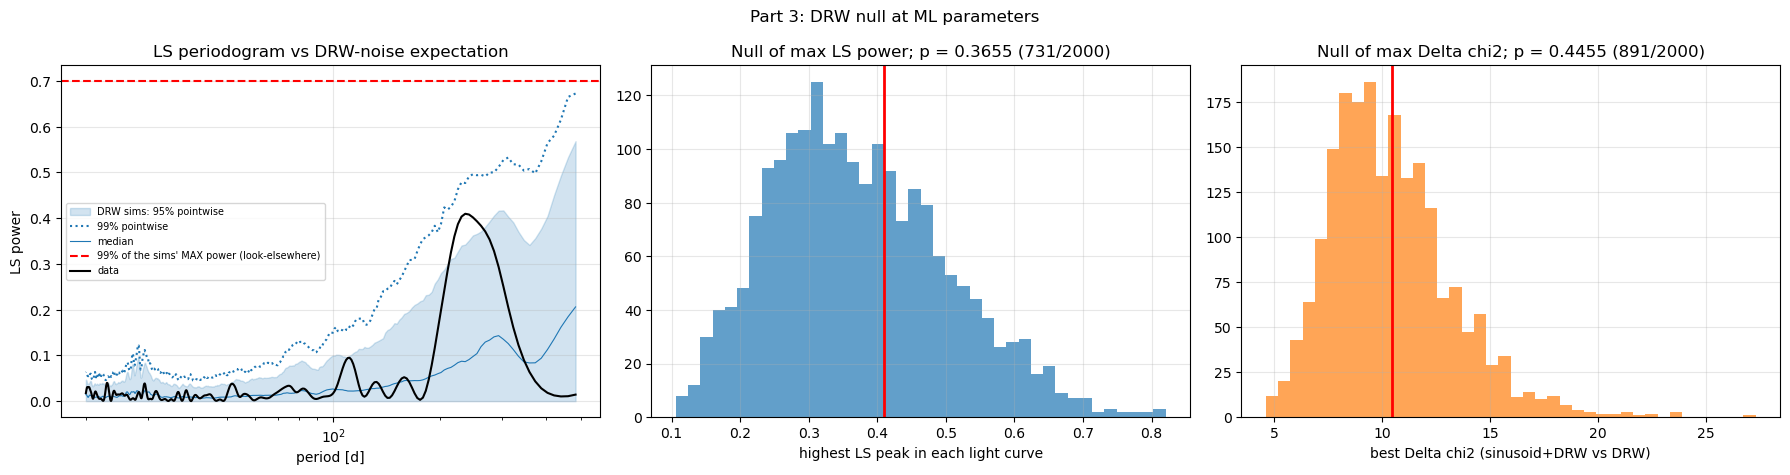

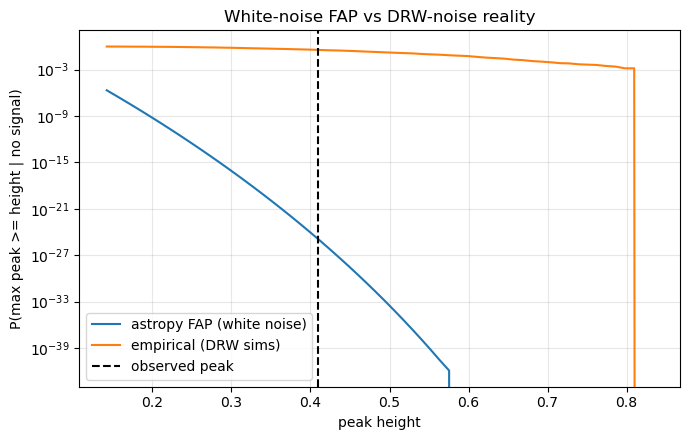


  case        tau[d]  sigma    p_LS    p_GLS   (sigma, mu re-fit at each tau)
  tau 16%       160   0.267  0.3515  0.4460
  tau ML        148   0.258  0.3655  0.4455
  tau 84%      1585   0.826  0.3310  0.4490

Best sinusoid: P = 205.6 d (Delta chi2 -1 range 197.8-215.3 d), A = 0.159 mag, A (16/50/84%) = 0.119/0.166/0.215 mag (amplitude is biased high when the signal is weak)

RULE p < 0.01 on both statistics -> NO evidence for a period (fail to reject DRW-only)
Honest reading: p_LS = 0.365, p_GLS = 0.446; the periodogram peak is within what DRW noise produces.


In [4]:
# ===================== Part 3: is it periodic? =====================
P_THRESH = 0.01      # <-- must match the rule written in the markdown cell above
NSIM = 2000

class SinScan:
    """GLS fit of mu + a cos + b sin under covariance C, for every trial period at once (whitening with Cholesky)."""
    def __init__(self, tt, C, periods):
        self.L = np.linalg.cholesky(C); n = len(tt); nP = len(periods)
        ph = 2 * np.pi * tt[None, :] / periods[:, None]
        X = np.stack([np.ones((nP, n)), np.cos(ph), np.sin(ph)], axis=-1)            # (nP, n, 3)
        Xw = solve_triangular(self.L, np.moveaxis(X, 1, 0).reshape(n, -1), lower=True).reshape(n, nP, 3)
        self.Xw = np.moveaxis(Xw, 0, 1)                                              # (nP, n, 3)
        self.M = self.Xw.transpose(0, 2, 1).reshape(nP * 3, n)
        self.Ainv = np.linalg.inv(np.einsum('pni,pnj->pij', self.Xw, self.Xw))
        self.one = solve_triangular(self.L, np.ones(n), lower=True); self.nP = nP
    def fit(self, Y):
        """Y: (n, nsim). Returns dchi2 (nsim, nP) vs constant-mean model and theta (nsim, nP, 3)."""
        YW = solve_triangular(self.L, Y, lower=True); k = Y.shape[1]
        b = (self.M @ YW).T.reshape(k, self.nP, 3)
        full = np.einsum('kpi,pij,kpj->kp', b, self.Ainv, b)
        const = (self.one @ YW)**2 / (self.one @ self.one)
        return full - const[:, None], np.einsum('pij,kpj->kpi', self.Ainv, b)
    def dchi2(self, Y, chunk=250):
        Y = np.atleast_2d(Y.T).T if Y.ndim == 1 else Y
        return np.vstack([self.fit(Y[:, i:i + chunk])[0] for i in range(0, Y.shape[1], chunk)])

def simulate_drw(tt, ee, mu, sig, tau, nsim, seed):
    n = len(tt); K = drw_k(tt[:, None] - tt[None, :], sig, tau)
    Lk = np.linalg.cholesky(K + 1e-10 * np.eye(n)); r = np.random.default_rng(seed)
    return (mu + Lk @ r.standard_normal((n, nsim)) + ee[:, None] * r.standard_normal((n, nsim))).T   # (nsim, n)

def periodicity_test(tt, yy, ee, mu, sig, tau, freq, nsim=NSIM, seed=0):
    periods = 1 / freq; C = cov(tt, ee, 'DRW', sig, tau); scan = SinScan(tt, C, periods)
    Y = simulate_drw(tt, ee, mu, sig, tau, nsim, seed)
    p_obs = LombScargle(tt, yy, ee).power(freq)
    p_sim = np.array([LombScargle(tt, Y[k], ee).power(freq) for k in range(nsim)], dtype=np.float32)
    d_obs = scan.dchi2(yy)[0]; d_sim = scan.dchi2(Y.T)
    th_obs = scan.fit(yy[:, None])[1][0]
    r = dict(freq=freq, periods=periods, scan=scan, Y=Y, p_obs=p_obs, p_sim=p_sim, d_obs=d_obs, d_sim=d_sim, th_obs=th_obs,
             pmax_obs=p_obs.max(), pmax_sim=p_sim.max(1), dmax_obs=d_obs.max(), dmax_sim=d_sim.max(1))
    r['p_ls'] = np.mean(r['pmax_sim'] >= r['pmax_obs']); r['p_gls'] = np.mean(r['dmax_sim'] >= r['dmax_obs'])
    r['k_ls'], r['k_gls'] = int((r['pmax_sim'] >= r['pmax_obs']).sum()), int((r['dmax_sim'] >= r['dmax_obs']).sum()); r['nsim'] = nsim
    return r

def plot_suite(tt, yy, ee, r, title=''):
    per = r['periods']
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.8)); ax = axs[0]
    q = np.percentile(r['p_sim'], [50, 95, 99], axis=0)
    ax.fill_between(per, 0, q[1], color='C0', alpha=0.2, label='DRW sims: 95% pointwise'); ax.plot(per, q[2], 'C0:', label='99% pointwise'); ax.plot(per, q[0], 'C0', lw=0.8, label='median')
    ax.axhline(np.percentile(r['pmax_sim'], 99), color='r', ls='--', label="99% of the sims' MAX power (look-elsewhere)")
    ax.plot(per, r['p_obs'], 'k', label='data'); ax.set(xscale='log', xlabel='period [d]', ylabel='LS power', title='LS periodogram vs DRW-noise expectation'); ax.legend(fontsize=7)
    ax = axs[1]; ax.hist(r['pmax_sim'], bins=40, color='C0', alpha=0.7); ax.axvline(r['pmax_obs'], color='r', lw=2)
    ax.set(xlabel='highest LS peak in each light curve', title=f"Null of max LS power; p = {r['p_ls']:.4f} ({r['k_ls']}/{r['nsim']})")
    ax = axs[2]; ax.hist(r['dmax_sim'], bins=40, color='C1', alpha=0.7); ax.axvline(r['dmax_obs'], color='r', lw=2)
    ax.set(xlabel='best Delta chi2 (sinusoid+DRW vs DRW)', title=f"Null of max Delta chi2; p = {r['p_gls']:.4f} ({r['k_gls']}/{r['nsim']})")
    plt.suptitle(title); plt.tight_layout(); plt.show()

# ---- 3.2 / 3.3 main test at the Part 2 maximum-likelihood parameters ----
res = periodicity_test(t, y, e, MU_ML, SIG_ML, TAU_ML, freq, NSIM, seed=11)
print(f"Observed: highest LS power {res['pmax_obs']:.4f} at P = {period[np.argmax(res['p_obs'])]:.1f} d;  best GLS Delta chi2 = {res['dmax_obs']:.2f} at P = {res['periods'][np.argmax(res['d_obs'])]:.1f} d")
print(f"EMPIRICAL p (LS peak, {NSIM} DRW sims):   {res['p_ls']:.4f}  ({res['k_ls']} of {NSIM}; resolution ~1/{NSIM})")
print(f"EMPIRICAL p (GLS Delta chi2):            {res['p_gls']:.4f}  ({res['k_gls']} of {NSIM})")
print(f"astropy FAP (white-noise null, baluev):  {fap_astropy:.3g}")
plot_suite(t, y, e, res, 'Part 3: DRW null at ML parameters')

# FAP calibration: astropy FAP vs empirical exceedance, as a function of peak height
lv = np.linspace(np.percentile(res['pmax_sim'], 1), max(res['pmax_obs'], np.percentile(res['pmax_sim'], 99.9)) * 1.02, 60)
emp = np.array([(res['pmax_sim'] >= x).mean() for x in lv]); ast = np.array([ls.false_alarm_probability(x, minimum_frequency=fmin, maximum_frequency=fmax) for x in lv])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(lv, ast, label='astropy FAP (white noise)'); ax.plot(lv, emp, label='empirical (DRW sims)'); ax.axvline(res['pmax_obs'], color='k', ls='--', label='observed peak')
ax.set(yscale='log', xlabel='peak height', ylabel='P(max peak >= height | no signal)', title='White-noise FAP vs DRW-noise reality'); ax.legend()
plt.tight_layout(); plt.show()

# ---- how p changes across the tau interval ----
TAU_LO, TAU_HI = tau_q[0], tau_q[2]
rows = []
for lab_, tau_ in [('tau 16%', TAU_LO), ('tau ML', TAU_ML), ('tau 84%', TAU_HI)]:
    ll_, s_, m_ = prof_at_tau(tau_, t, y, e)        # re-maximise sigma, mu at this tau
    rr = res if lab_ == 'tau ML' else periodicity_test(t, y, e, m_, s_, tau_, freq, NSIM, seed=12)
    rows.append((lab_, tau_, s_, rr['p_ls'], rr['p_gls']))
print("\n  case        tau[d]  sigma    p_LS    p_GLS   (sigma, mu re-fit at each tau)")
for r_ in rows: print(f"  {r_[0]:9s} {r_[1]:7.0f} {r_[2]:7.3f}  {r_[3]:6.4f}  {r_[4]:6.4f}")

# ---- period / amplitude uncertainty for the best sinusoid ----
ib = np.argmax(res['d_obs']); Pb = res['periods'][ib]
ffine = np.linspace(1 / (Pb * 1.15), 1 / (Pb / 1.15), 1500); C_ml = cov(t, e, 'DRW', SIG_ML, TAU_ML)
sc_f = SinScan(t, C_ml, 1 / ffine); d_f = sc_f.dchi2(y)[0]; th_f = sc_f.fit(y[:, None])[1][0]; j = np.argmax(d_f)
ok = d_f >= d_f[j] - 1; Plo, Phi = 1 / ffine[ok].max(), 1 / ffine[ok].min(); th = th_f[j]
draws = np.random.default_rng(3).multivariate_normal(th, sc_f.Ainv[j], size=20000); Ad = np.hypot(draws[:, 1], draws[:, 2]); Aq = np.percentile(Ad, [16, 50, 84])
print(f"\nBest sinusoid: P = {1/ffine[j]:.1f} d (Delta chi2 -1 range {Plo:.1f}-{Phi:.1f} d), A = {np.hypot(th[1], th[2]):.3f} mag, "
      f"A (16/50/84%) = {Aq[0]:.3f}/{Aq[1]:.3f}/{Aq[2]:.3f} mag (amplitude is biased high when the signal is weak)")

claim = (res['p_ls'] < P_THRESH) and (res['p_gls'] < P_THRESH)
print(f"\nRULE p < {P_THRESH} on both statistics ->", "EVIDENCE for a period" if claim else "NO evidence for a period (fail to reject DRW-only)")
if not claim:
    print(f"Honest reading: p_LS = {res['p_ls']:.3f}, p_GLS = {res['p_gls']:.3f}; the periodogram peak is within what DRW noise produces.")

**ANSWER (the decision rule first, then the verdict):**
1. See above,p=0.01
2. you can see the FAP value is super far off. Any tall peak it assuems is so outside of the given x sigma values, it assuems it is all signifigant, though this is not true, there is intrinsic scatter and variation over pulsar periods not everyhting thats just above the sigma x values is signifigant.2. The p_LS = 0.365, p_GLS = 0.446 respectivly, which are both much higher than the FAP. The white noise being random can't explain the peaks (outside of significance, low FAP) but the DRW effectivley removes any signifigance from the data
3. It barely moved, when the tau value changes the LS peak swings from 0.33 to 0.36, and the GLS peak is also roughly the same. So, conclusion doesn't depent on tau
4. There appears to be no candidate. The peak would have to be outside of the DRW noise perameters, which it is not. I would not claim there is a quasar here, the p values are well above 0.01 or even 0.05. 

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


=== ERROR 1: white-noise FAP used as significance ===
AI's FAP for my peak (white-noise null): 1.26e-25
Empirical p from 2000 DRW-only sims: 0.365 (731/2000)
  DRW-only light curves (NO signal) the AI's rule calls periodic at FAP < 0.05: 100.0%
  DRW-only light curves (NO signal) the AI's rule calls periodic at FAP < 0.01: 100.0%
  DRW-only light curves (NO signal) the AI's rule calls periodic at FAP < 0.001: 100.0%
Power needed for 1% significance: white noise 0.077 vs DRW sims 0.699; my peak 0.410

=== ERROR 2: squared-exponential kernel assumed, no comparison ===
lnL DRW = 316.17, lnL SE = 298.62, Delta lnL = 17.55, likelihood ratio = 4.19e+07
SE lnL from every start (single-start check): [298.623 298.623 298.623 298.623 298.623 298.623 298.623 298.623 298.623
 298.623 298.623 298.623]


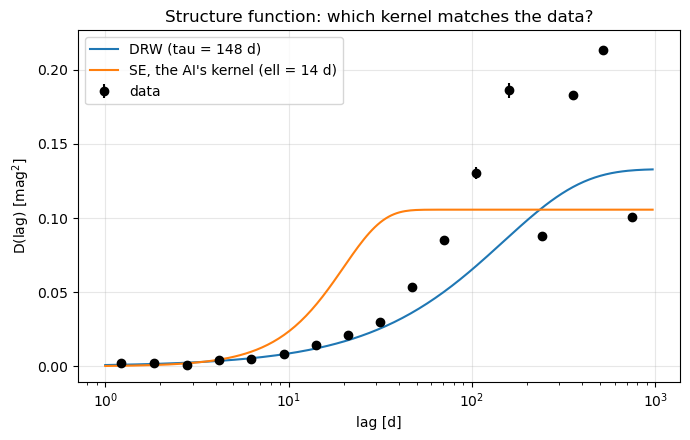

In [5]:
print("=== ERROR 1: white-noise FAP used as significance ===")
pm = np.asarray(res['pmax_sim'], dtype=float)
fap_sims = np.atleast_1d(ls.false_alarm_probability(pm, minimum_frequency=fmin, maximum_frequency=fmax))
print(f"AI's FAP for my peak (white-noise null): {fap_astropy:.3g}")
print(f"Empirical p from {res['nsim']} DRW-only sims: {res['p_ls']:.3f} ({res['k_ls']}/{res['nsim']})")
for thr in (0.05, 0.01, 1e-3):
    print(f"  DRW-only light curves (NO signal) the AI's rule calls periodic at FAP < {thr}: {np.mean(fap_sims < thr):.1%}")
lvl_wn = float(ls.false_alarm_level(0.01, minimum_frequency=fmin, maximum_frequency=fmax))
lvl_drw = float(np.percentile(pm, 99))
print(f"Power needed for 1% significance: white noise {lvl_wn:.3f} vs DRW sims {lvl_drw:.3f}; my peak {res['pmax_obs']:.3f}")

print("\n=== ERROR 2: squared-exponential kernel assumed, no comparison ===")
print(f"lnL DRW = {lnL_drw:.2f}, lnL SE = {lnL_se:.2f}, Delta lnL = {lnL_drw - lnL_se:.2f}, likelihood ratio = {np.exp(lnL_drw - lnL_se):.2e}")
print("SE lnL from every start (single-start check):", np.round(sorted([z[0] for z in ml_se], reverse=True), 3))
lagg = np.logspace(0, np.log10(T), 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(lag_sf, D_sf, De_sf, fmt='ko', label='data')
ax.plot(lagg, 2 * SIG_ML**2 * (1 - np.exp(-lagg / TAU_ML)), label=f'DRW (tau = {TAU_ML:.0f} d)')
ax.plot(lagg, 2 * SIG_SE**2 * (1 - np.exp(-0.5 * (lagg / ELL_SE)**2)), label=f"SE, the AI's kernel (ell = {ELL_SE:.0f} d)")
ax.set(xscale='log', xlabel='lag [d]', ylabel='D(lag) [mag$^2$]', title='Structure function: which kernel matches the data?'); ax.legend()
plt.tight_layout(); plt.show()


**REFEREE REPORT:**

1.  It takes the FAP noise to be the signifigance, but thats just the white noise false alarm probability. Just because its low, that only means white noise assuming an independent Gaussian noise wouldn't explain the signal. Quasars are not independent, random noise, however, they are a dampended random walk, so this is wrong. Claude coded something to show that FAP predicts a quasar being detected evenif there isn't one in almost every simulation.

2.   The kernel doesn't match with mine, and thats because it never actually tests it. It is not supposed to be smooth variablilty, and it uses a squared exponential and doesn't do a comparison. It being too smooth means its likely missing data, and you can see how off the AI kernel is when it flattens out. Mine didn't rely on this same logic.

3. It says a 62% coverage is equally validating to a 68% coverage, but there is clearly a difference there. Also, the R^2 value is messured against the mean, which contains large season to season swings, so any R^2 value can't be trusted as much. Mine didn't rely on or get stuck on 62%, it actually used the 68% interval. 



## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [6]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18aaudoro: 714 g-band detections from the live API
ZTF18aaudoro: MJD 59019.3 to 61076.5 (5.6 yr); the last detection is MJD 61076.5; today is MJD 61354


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


714 detections -> 523 nightly means over 2057 d; last detection MJD 61076.5, today MJD 61354 (278 d ago); median cadence 2.0 d
live DRW ML: mu = 18.460, sigma = 0.155 mag, tau = 588 d, T/tau = 3.5
LS peak P = 321.4 d, power 0.3587, astropy FAP = 8.02e-48
EMPIRICAL p: LS = 0.1970, GLS = 0.6270  -> no evidence of a period


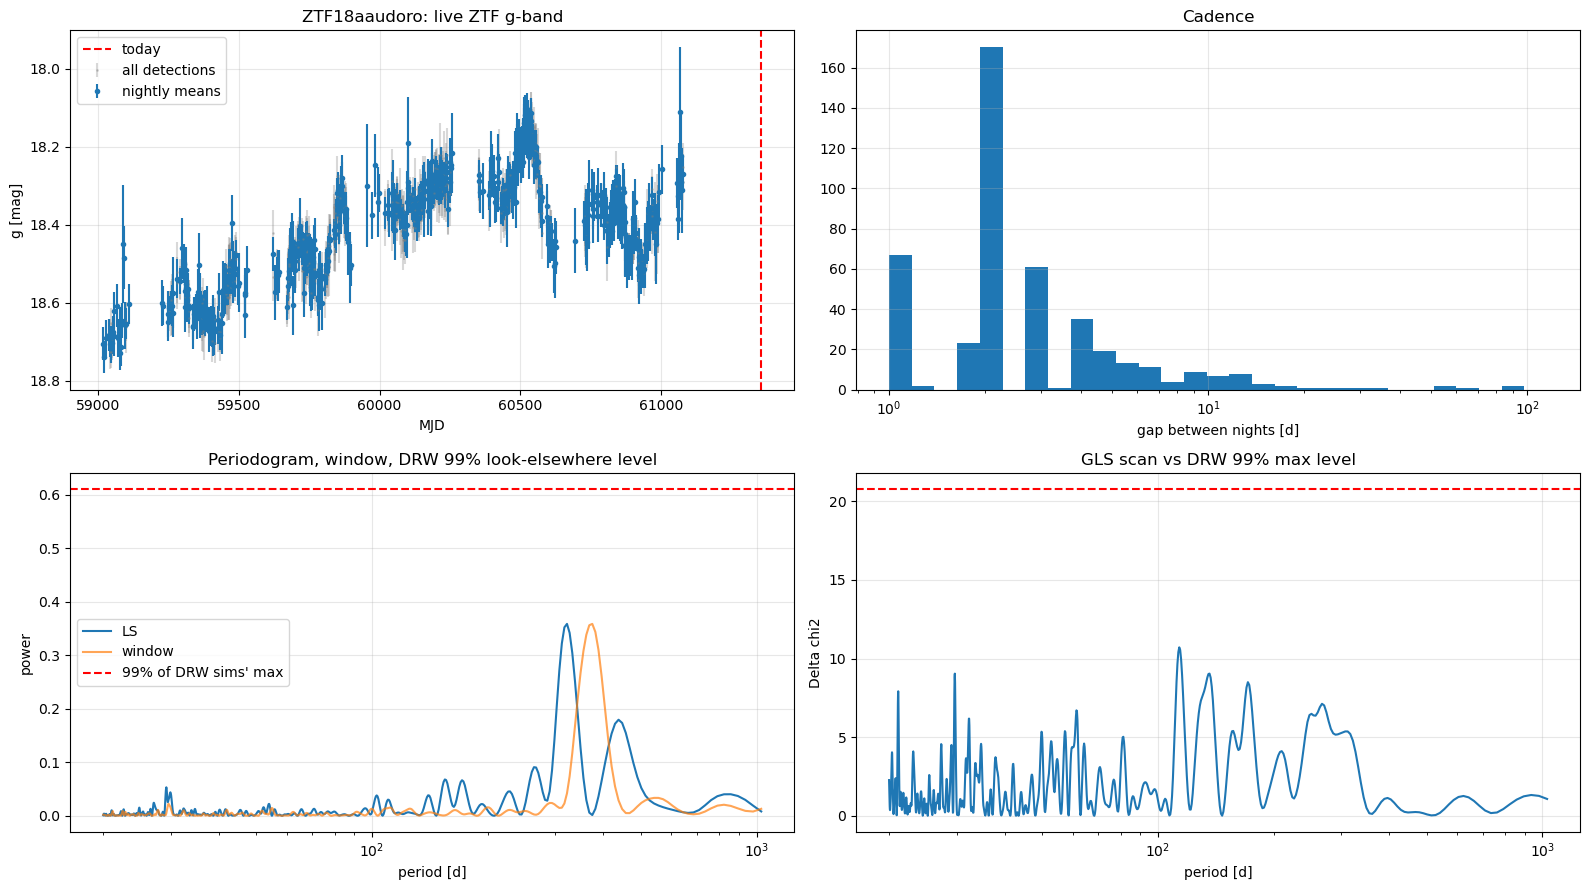

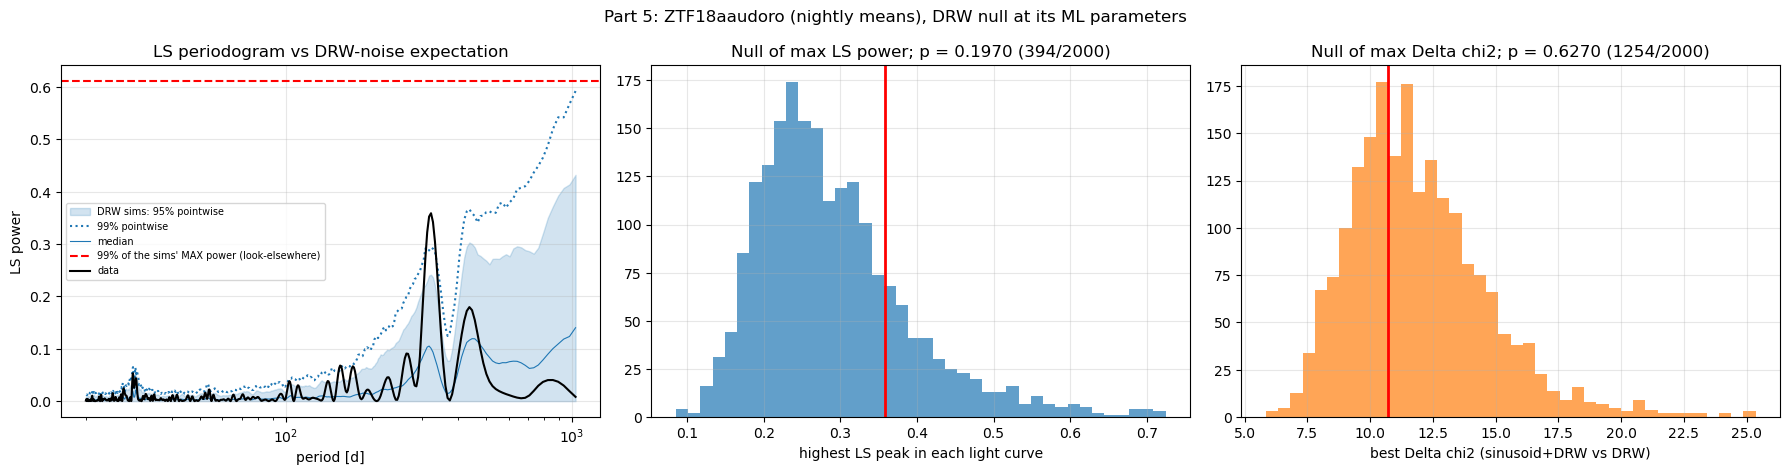

In [7]:
# ===================== Part 5: the live light curve =====================
# CRITERION (decided before running): call it periodic only if the empirical p < 0.01 on BOTH the LS-peak and
# the DRW-GLS Delta chi2 statistics against DRW simulations (same rule as Part 3), using this object's own ML DRW fit.
# Raw ZTF points -> nightly weighted means.
night = np.floor(mjd).astype(int); un, inv = np.unique(night, return_inverse=True)
wsum = np.bincount(inv, weights=1 / merr**2)
tn = np.bincount(inv, weights=mjd) / np.bincount(inv); yn = np.bincount(inv, weights=mag / merr**2) / wsum; en = 1 / np.sqrt(wsum)
tl = tn - tn.min(); Tl = tl.max() - tl.min(); Nl = tl.size
print(f"{mjd.size} detections -> {Nl} nightly means over {Tl:.0f} d; last detection MJD {mjd.max():.1f}, today MJD {Time.now().mjd:.0f} "
      f"({Time.now().mjd - mjd.max():.0f} d ago); median cadence {np.median(np.diff(tl)):.1f} d")

mlL = fit_ml(tl, yn, en, 'DRW', starts=[(np.log(s_), np.log(l_)) for s_ in [0.1, 0.4] for l_ in [30, 200, 1000, 3000]])
thL = mlL[0][1]; muL, sigL, tauL = thL[0], np.exp(thL[1]), np.exp(thL[2])
print(f"live DRW ML: mu = {muL:.3f}, sigma = {sigL:.3f} mag, tau = {tauL:.0f} d, T/tau = {Tl/tauL:.1f}")
fmL, fxL = 2 / Tl, 1 / 20.; dfL = 1 / (10 * Tl); freqL = np.arange(fmL, fxL + dfL / 2, dfL)
lsL = LombScargle(tl, yn, en); powL = lsL.power(freqL); winL = LombScargle(tl, np.ones_like(yn), fit_mean=False, center_data=False).power(freqL)
fapL = lsL.false_alarm_probability(powL.max(), minimum_frequency=fmL, maximum_frequency=fxL)
print(f"LS peak P = {1/freqL[np.argmax(powL)]:.1f} d, power {powL.max():.4f}, astropy FAP = {fapL:.3g}")
resL = periodicity_test(tl, yn, en, muL, sigL, tauL, freqL, NSIM, seed=21)
print(f"EMPIRICAL p: LS = {resL['p_ls']:.4f}, GLS = {resL['p_gls']:.4f}  ->", "PERIODIC by the rule" if (resL['p_ls'] < P_THRESH and resL['p_gls'] < P_THRESH) else "no evidence of a period")

fig, axs = plt.subplots(2, 2, figsize=(16, 9))
ax = axs[0, 0]; ax.errorbar(mjd, mag, merr, fmt='.', ms=2, alpha=0.3, color='gray', label='all detections'); ax.errorbar(tn, yn, en, fmt='o', ms=3, label='nightly means')
ax.axvline(Time.now().mjd, color='r', ls='--', label='today'); ax.invert_yaxis(); ax.set(xlabel='MJD', ylabel='g [mag]', title=f'{OID}: live ZTF g-band'); ax.legend()
axs[0, 1].hist(np.diff(tl), bins=np.logspace(0, np.log10(max(np.diff(tl).max(), 10)), 30)); axs[0, 1].set(xscale='log', xlabel='gap between nights [d]', title='Cadence')
ax = axs[1, 0]; ax.plot(1 / freqL, powL, label='LS'); ax.plot(1 / freqL, winL * powL.max() / winL.max(), alpha=0.7, label='window'); ax.axhline(np.percentile(resL['pmax_sim'], 99), color='r', ls='--', label="99% of DRW sims' max")
ax.set(xscale='log', xlabel='period [d]', ylabel='power', title='Periodogram, window, DRW 99% look-elsewhere level'); ax.legend()
ax = axs[1, 1]; ax.plot(resL['periods'], resL['d_obs']); ax.axhline(np.percentile(resL['dmax_sim'], 99), color='r', ls='--'); ax.set(xscale='log', xlabel='period [d]', ylabel='Delta chi2', title='GLS scan vs DRW 99% max level')
plt.tight_layout(); plt.show()
plot_suite(tl, yn, en, resL, f'Part 5: {OID} (nightly means), DRW null at its ML parameters')

**ANSWER (the criterion first, then the result):**
The p value would need to be much lower, below the limit for detection.
There is no evidence for aperiod
this data comes from many more days, 5.6 years in total. Theres a few gaps in the data, that with more days I would like to fill in. The P values are simply just not where they need to be, so there is no candidate that I can see. The last detection was also 278 days ago, meaning any period within that time probably couldn't have been repeated as we haven't seen it since. 

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I started with the use of Copilot to code, but when that got annoying, I switched to claude for the rest of the code. It struggled a lot towards the start and running the simulations was the most difficult part, as if it made an error, it would likely take a long time for me to find out about it and then I would need to rerun it all again. I wrote all answers on my own at first, but plugged my answer to question 2 into claude and asked it to refrase and explain it to me in more detail as I was confused on some of the points even I was making. The rest of the asnwers are still fully my own, and I ensured claude didn't change the substance of my text. 

**REFLECTION:**

Claude was making errors in the random walk process. It still produced numbers in the end, even though the step size wasn't changing. The numbers look right,too. Only after looking at the actual simulations and seeing that the step sizes weren't changing was I able to fix it and it changed the numbers to be what they are now. I almost missed this at first, as it was after it finally didn't give me any error messages. 
**VERIFICATION PLAN:**

I asked Claude to write code that verified my Cholesky stuff, wiht some simulated data set, MCM covergence checks, synthetic data, false positives, and whatecver else it needed to run to make sure my results looked correct. It appeared to all look good, and I gave it the outputs to make sure, as well. 

In [8]:
# ===================== Verification A: quick checks =====================
from scipy.stats import multivariate_normal
import time

# --- 1. likelihood vs brute force (30-point subset, both kernels) ---
idx = np.sort(np.random.default_rng(0).choice(N, 30, replace=False))
for kn, th_ in (('DRW', th_drw), ('SE', th_se)):
    C_ = cov(t[idx], e[idx], kn, np.exp(th_[1]), np.exp(th_[2]))
    mine = log_like(th_, t[idx], y[idx], e[idx], kn)
    ref = multivariate_normal(mean=np.full(30, th_[0]), cov=C_).logpdf(y[idx])
    print(f"[1] {kn}: my lnL = {mine:.8f}, scipy = {ref:.8f}, diff = {abs(mine - ref):.1e}", "PASS" if abs(mine - ref) < 1e-6 else "FAIL")
    dg = np.diag(C_) - np.exp(2 * th_[1])
    print(f"    noise on diagonal = e^2: max |diff| = {np.max(np.abs(dg - e[idx]**2)):.1e}")

# --- 2. optimiser robustness: all starts agree, and the profile does not beat the optimiser ---
l_all = np.array([z[0] for z in ml_drw]); t_all = np.array([np.exp(z[1][2]) for z in ml_drw])
print(f"\n[2] DRW lnL over {len(l_all)} starts: spread = {l_all.max() - l_all.min():.2e}; tau range among starts with lnL within 0.01 of best: "
      f"{t_all[l_all > l_all.max() - 0.01].min():.0f}-{t_all[l_all > l_all.max() - 0.01].max():.0f} d")
print(f"    best profile-grid lnL = {lnL_prof.max():.4f} vs optimiser lnL = {lnL_drw:.4f}",
      "PASS" if lnL_prof.max() <= lnL_drw + 1e-3 else "CHECK: profile beats optimiser -> optimiser stuck or grid/sigma-bounds issue")
l_se = np.array([z[0] for z in ml_se]); print(f"    SE lnL over starts: min {l_se.min():.3f}, max {l_se.max():.3f}")

# --- 3. MCMC convergence ---
print("\n[3] MCMC convergence (want: chain > 50 autocorr times, split-Rhat < 1.1, halves agree, little mass at the tau bounds)")
for k_, nm in enumerate(['mu', 'ln sigma', 'ln tau']):
    ta = tau_int(post[:, :, k_]); rh = split_rhat(post[:, :, k_])
    h1, h2 = np.median(post[:len(post) // 2, :, k_]), np.median(post[len(post) // 2:, :, k_])
    print(f"    {nm:9s}: chain/tau_int = {post.shape[0] / ta:5.0f}, Rhat = {rh:.3f}, halves {h1:.3f}/{h2:.3f}",
          "PASS" if (post.shape[0] / ta > 50 and rh < 1.1) else "CHECK")
print(f"    posterior mass with tau > 0.9*upper bound: {np.mean(tau_s > 3600):.3f}; tau < 1.1*lower bound: {np.mean(tau_s < 11):.3f}")

# --- 7. sensitivity of the periodicity verdict to tau (from Part 3) ---
print("\n[7] p-value across the tau interval (Part 3 table):")
for r_ in rows: print(f"    {r_[0]:9s} tau = {r_[1]:6.0f}  p_LS = {r_[3]:.3f}  p_GLS = {r_[4]:.3f}")
print("    verdict flips if p crosses your pre-registered threshold across this range:",
      any((r_[3] < P_THRESH) != (rows[1][3] < P_THRESH) for r_ in rows))

# --- 8. Monte-Carlo resolution of the p-values ---
for nm, p_, n_ in (('LS', res['p_ls'], res['nsim']), ('GLS', res['p_gls'], res['nsim'])):
    print(f"[8] p_{nm} = {p_:.3f} +/- {np.sqrt(p_ * (1 - p_) / n_):.3f} (binomial, {n_} sims)")
print(f"    sims needed to resolve p = {P_THRESH} to +/-20%: ~{int((1 - P_THRESH) / (P_THRESH * 0.2**2))}")

[1] DRW: my lnL = 16.90246574, scipy = 16.90246574, diff = 1.8e-14 PASS
    noise on diagonal = e^2: max |diff| = 6.6e-18
[1] SE: my lnL = 9.99472706, scipy = 9.99472706, diff = 4.6e-14 PASS
    noise on diagonal = e^2: max |diff| = 1.0e-17

[2] DRW lnL over 12 starts: spread = 3.38e-08; tau range among starts with lnL within 0.01 of best: 148-148 d
    best profile-grid lnL = 316.1696 vs optimiser lnL = 316.1732 PASS
    SE lnL over starts: min 298.623, max 298.623

[3] MCMC convergence (want: chain > 50 autocorr times, split-Rhat < 1.1, halves agree, little mass at the tau bounds)
    mu       : chain/tau_int =    71, Rhat = 1.018, halves 19.684/19.677 PASS
    ln sigma : chain/tau_int =    57, Rhat = 1.021, halves -0.833/-0.850 PASS
    ln tau   : chain/tau_int =    58, Rhat = 1.019, halves 6.052/6.025 PASS
    posterior mass with tau > 0.9*upper bound: 0.017; tau < 1.1*lower bound: 0.000

[7] p-value across the tau interval (Part 3 table):
    tau 16%   tau =    160  p_LS = 0.351  

In [9]:
# ===================== Verification B: do my intervals cover the truth? =====================
NREP = 30                              # raise to ~200 for a real calibration (time the first replicate!)
TRUTH = (MU_ML, SIG_ML, TAU_ML)        # known-truth values used to simulate
taus_g = np.logspace(1, np.log10(4000), 40)
sigs_g = np.logspace(np.log10(0.03), np.log10(1.5), 30)

def fit_quick(tt, yy, ee, kern='DRW', starts=((0.1, 30), (0.3, 300), (0.1, 1000))):
    return fit_ml(tt, yy, ee, kern, starts=[(np.log(s_), np.log(l_)) for s_, l_ in starts])[0]

def prof_at_sigma(sig, tt, yy, ee):
    ones_ = np.ones(len(yy))
    def f(lt):
        cf = cho_factor(cov(tt, ee, 'DRW', sig, np.exp(lt)), lower=True)
        mu_ = (ones_ @ cho_solve(cf, yy)) / (ones_ @ cho_solve(cf, ones_))
        return -log_like([mu_, np.log(sig), lt], tt, yy, ee, 'DRW')
    return -minimize_scalar(f, bounds=LNT_B, method='bounded', options=dict(xatol=1e-3)).fun

def covers(lo, hi, truth_ln):
    return (lo is None or truth_ln >= lo) and (hi is None or truth_ln <= hi)

Ysyn = simulate_drw(t, e, *TRUTH, NREP, seed=2024)           # (NREP, N), no sinusoid
out = dict(cov_tau=[], cov_sig=[], bias_lntau=[], inside=[], n_held=[])
t0 = time.time()
for i in range(NREP):
    yy = Ysyn[i]
    lnl, th_i, _ = fit_quick(t, yy, e)
    # tau profile interval
    pt = np.array([prof_at_tau(tt_, t, yy, e)[0] for tt_ in taus_g]); dt = 2 * (max(pt.max(), lnl) - pt)
    lo, b, hi = profile_interval(np.log(taus_g), dt)
    out['cov_tau'].append(covers(lo, hi, np.log(TRUTH[2])))
    # sigma profile interval
    ps = np.array([prof_at_sigma(s_, t, yy, e) for s_ in sigs_g]); ds = 2 * (max(ps.max(), lnl) - ps)
    lo2, b2, hi2 = profile_interval(np.log(sigs_g), ds)
    out['cov_sig'].append(covers(lo2, hi2, np.log(TRUTH[1])))
    out['bias_lntau'].append(th_i[2] - np.log(TRUTH[2]))
    # block hold-out, refit on training data only (Part 2 'held'/'tr' masks)
    _, th_tr, _ = fit_quick(t[tr], yy[tr], e[tr], starts=((0.1, 30), (0.3, 300)))
    m_, v_ = gp_predict(t[held], t[tr], yy[tr], e[tr], 'DRW', th_tr)
    out['inside'].append(np.sum(np.abs(yy[held] - m_) < np.sqrt(v_ + e[held]**2))); out['n_held'].append(held.sum())
    if i == 0: print(f"first replicate took {time.time() - t0:.0f} s -> expect ~{(time.time() - t0) * NREP / 60:.0f} min total")

ct, cs = np.mean(out['cov_tau']), np.mean(out['cov_sig'])
se_ = lambda p: np.sqrt(p * (1 - p) / NREP)
ins = np.sum(out['inside']) / np.sum(out['n_held'])
print(f"\n[4] 68% profile interval contains the true tau  in {ct:.0%} +/- {se_(ct):.0%} of {NREP} runs")
print(f"[4] 68% profile interval contains the true sigma in {cs:.0%} +/- {se_(cs):.0%} of {NREP} runs   (target 68%)")
print(f"    median bias in ln tau = {np.median(out['bias_lntau']):+.2f} (ML tau is typically biased with T/tau this small)")
print(f"[9] block-CV 68% predictive band contains {ins:.0%} of held-out points (target 68%; points within a block are correlated, so the real error bar is wider than binomial)")
print("    Failure looks like: coverage near 40% (intervals too narrow), near 95% (too wide), or a large bias.")

# nearest-training-neighbour distances: how hard is the hold-out?
nn_b = np.abs(t[held][:, None] - t[tr][None, :]).min(axis=1)
print(f"    held-out epochs sit a median {np.median(nn_b):.1f} d (max {nn_b.max():.0f} d) from the nearest training epoch; tau = {TAU_ML:.0f} d")

first replicate took 4 s -> expect ~2 min total

[4] 68% profile interval contains the true tau  in 63% +/- 9% of 30 runs
[4] 68% profile interval contains the true sigma in 67% +/- 9% of 30 runs   (target 68%)
    median bias in ln tau = -0.40 (ML tau is typically biased with T/tau this small)
[9] block-CV 68% predictive band contains 69% of held-out points (target 68%; points within a block are correlated, so the real error bar is wider than binomial)
    Failure looks like: coverage near 40% (intervals too narrow), near 95% (too wide), or a large bias.
    held-out epochs sit a median 13.0 d (max 24 d) from the nearest training epoch; tau = 148 d


In [10]:
# ===================== Verification C: false positives and power of the Part 3 test =====================
from scipy.stats import kstest
pool = np.asarray(res['pmax_sim'], dtype=float)           # null distribution of the max LS power (DRW, ML parameters)

def run_ls(Y):
    pk = np.empty(len(Y)); Ph = np.empty(len(Y))
    for k_ in range(len(Y)):
        pw = LombScargle(t, Y[k_], e).power(freq); pk[k_] = pw.max(); Ph[k_] = 1 / freq[np.argmax(pw)]
    return pk, Ph
pval = lambda pk: np.array([(np.sum(pool >= x) + 1) / (len(pool) + 1) for x in pk])

# --- 5. false-positive rate: DRW-only light curves, none containing a signal ---
NNULL = 400
pk0, _ = run_ls(simulate_drw(t, e, *TRUTH, NNULL, seed=777))   # new seed: independent of the pool
p0 = pval(pk0)
print("[5] FALSE POSITIVES (no signal planted)")
for thr in (0.05, 0.01):
    f_ = np.mean(p0 < thr); print(f"    fraction with p < {thr}: {f_:.3f} +/- {np.sqrt(f_ * (1 - f_) / NNULL):.3f}  (target {thr})")
print(f"    KS test of p-values vs uniform: p = {kstest(p0, 'uniform').pvalue:.2f}  (small => the p-value is miscalibrated)")

# --- 6. power: plant a sinusoid of known period and amplitude ---
NPOW = 200
rp = np.random.default_rng(5)
print("\n[6] POWER (detections at p < %.2f; period recovered = peak within 5%% of the planted period)" % P_THRESH)
print("    P_true[d]  amp[mag]   detect   recovered|detected")
for Ptrue in (100.0, 236.0):
    base = simulate_drw(t, e, *TRUTH, NPOW, seed=int(Ptrue) + 1)
    for A in (0.05, 0.10, 0.16, 0.25):
        ph0 = rp.uniform(0, 2 * np.pi, NPOW)
        Yp = base + A * np.sin(2 * np.pi * t[None, :] / Ptrue + ph0[:, None])
        pkp, Php = run_ls(Yp); det = pval(pkp) < P_THRESH
        rec = np.abs(Php - Ptrue) / Ptrue < 0.05
        print(f"    {Ptrue:8.0f}  {A:8.2f}   {det.mean():6.0%}   {(rec[det].mean() if det.any() else np.nan):.0%}")
print("    Read this against your fitted amplitude (~0.16 mag): if a planted signal that size is rarely detected,")
print("    'no evidence' means 'the data cannot tell', not 'there is none'.")

[5] FALSE POSITIVES (no signal planted)
    fraction with p < 0.05: 0.048 +/- 0.011  (target 0.05)
    fraction with p < 0.01: 0.015 +/- 0.006  (target 0.01)
    KS test of p-values vs uniform: p = 0.24  (small => the p-value is miscalibrated)

[6] POWER (detections at p < 0.01; period recovered = peak within 5% of the planted period)
    P_true[d]  amp[mag]   detect   recovered|detected
         100      0.05       1%   0%
         100      0.10       1%   0%
         100      0.16       0%   0%
         100      0.25       2%   100%
         236      0.05       2%   0%
         236      0.10       0%   0%
         236      0.16       1%   50%
         236      0.25      14%   81%
    Read this against your fitted amplitude (~0.16 mag): if a planted signal that size is rarely detected,
    'no evidence' means 'the data cannot tell', not 'there is none'.
